In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys, os
from scipy import stats
from itertools import combinations
import seaborn as sns
from statannotations.Annotator import Annotator
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../..")))
from scripts.questionnaires_analysis import factor_grouping, big_5, cognitive_flexibility

In [2]:
pd.set_option('display.max_columns', 100)

In [3]:
out_folder = '/Users/emma/projects/cognoscolab/rassereno/out/'

## MAS-IT Plots

In [4]:
physics_mas_it = pd.read_csv(f'{out_folder}formatting/physics_2025/mas_it_fisica_2025.csv')

# selazionare solo i partecipanti del gruppo STEM
stem_group_mas_it = physics_mas_it[physics_mas_it['participant_id'].str.startswith('fisica_stem')]

In [5]:
# mas_it factors, without the reduntant and unstable ones (MAS-IT questionnaire)
mas_factor_1 = [1, 4, 5, 7, 8, 11, 12, 13, 14]				
mas_factor_2 = [3, 6, 9]				
mas_factor_3 = [18, 19, 20, 21, 22]

mas_factors  = [mas_factor_1, mas_factor_2, mas_factor_3]
# create a df with the scores of each factor
mas_factors_df = factor_grouping(mas_factors, stem_group_mas_it, 'mas_it', sum=False).reset_index(drop=True)

# make labels based on the pre or post sessions
mas_factors_df['session'] = np.where(stem_group_mas_it['participant_id'].str.endswith('1'),'pre','post')

mas_factors_df = mas_factors_df.melt(id_vars='session', var_name='factor', value_name='score')

mas_factors_df = mas_factors_df.explode('score')

In [6]:
def pvalues_annotations(ax, df = pd.DataFrame(), var1 = str, var2 = str, test='Kruskal', alpha=0.05):
    n_questionnaire = df[var1].unique()
    factors = df[var2].unique()

    pairs = [((factor, n_questionnaire[0]), (factor, n_questionnaire[1])) for factor in factors]

    annotator = Annotator(
        ax,
        pairs=pairs,
        data=df,
        x=var2, 
        y="score", 
        hue=var1
    )

    annotator.configure(test=test, loc='inside', hide_non_significant=True)
    
    annotator.apply_test()
    annotator.annotate()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

mas_it_factor_1_pre vs. mas_it_factor_1_post: Kruskal-Wallis independent samples (pairwise between groups), P_val:2.795e-02 Stat=4.831e+00


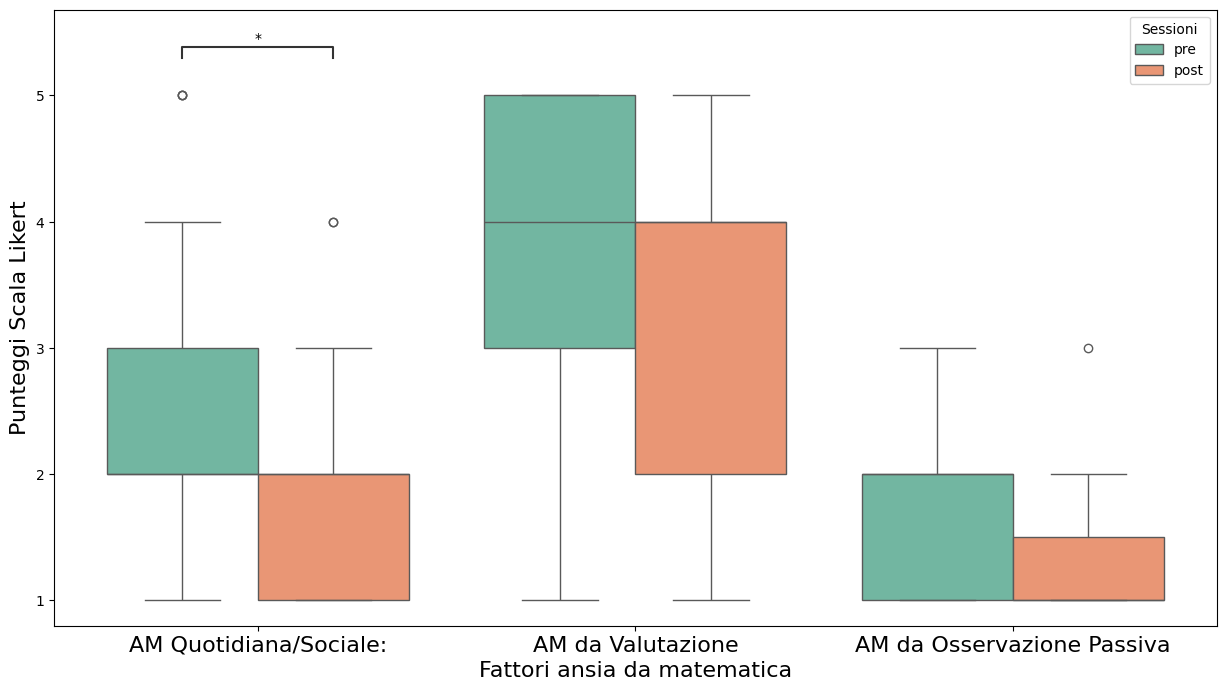

In [7]:
plt.figure(figsize=(15,8))
ax = sns.boxplot(
    data=mas_factors_df,
    x="factor",
    y="score",
    hue="session",
    palette="Set2"
)

pvalues_annotations(ax, df = mas_factors_df, var1 = 'session', var2 = 'factor')

ax.set_xticks(range(3))
ax.set_xticklabels(
    labels=["AM Quotidiana/Sociale:", "AM da Valutazione", "AM da Osservazione Passiva"],
    fontsize=16
)

plt.xlabel('Fattori ansia da matematica', fontsize=16)

plt.yticks(range(1, 6))
plt.ylabel('Punteggi Scala Likert', fontsize=16)

plt.legend(title='Sessioni')

plt.savefig(f'{out_folder}analysis/stem_group/mas_it_boxplot.png')

plt.show()

## Questionnaires

In [8]:
questionnaires_2025 = pd.read_csv(f'{out_folder}formatting/all_students_2025/all_questionnaires_2025.csv')

# selazionare solo i partecipanti del gruppo STEM
stem_group_questionnaires = questionnaires_2025[questionnaires_2025['participant_id'].str.startswith('fisica_stem')].reset_index(drop=True)

In [9]:
stem_group_questionnaires

,participant_id,gender,percieved_abilities,Q20_1,cfs_1,cfs_2,cfs_3,cfs_4,cfs_5,cfs_6,cfs_7,cfs_8,cfs_9,cfs_10,cfs_11,cfs_12,state_anxiety_1,state_anxiety_2,state_anxiety_3,state_anxiety_4,state_anxiety_5,state_anxiety_6,state_anxiety_7,state_anxiety_8,state_anxiety_9,state_anxiety_10,state_anxiety_11,state_anxiety_12,state_anxiety_13,state_anxiety_14,state_anxiety_15,state_anxiety_16,state_anxiety_17,state_anxiety_18,big_5_1,big_5_2,big_5_3,big_5_4,big_5_5,big_5_6,big_5_7,big_5_8,big_5_9,big_5_10,mas_it_1,mas_it_3,mas_it_4,mas_it_5,mas_it_6,mas_it_7,mas_it_8,mas_it_9,mas_it_11,mas_it_12,mas_it_13,mas_it_14,mas_it_18,mas_it_19,mas_it_20,mas_it_21,mas_it_22,mas_it_23
0,fisica_stem_001_1,F,4,20.0,4,4,2,4,4,5,4,3,2,2,5,2,1,1,3,3,1,3,3,2,2,2,3,3,1,2,3,3,2,3,2.0,4.0,2.0,1.0,1.0,5.0,4.0,5.0,4.0,5.0,2,3,1,1,1,2,1,2,1,3,1,4,2,1,2,1,1,2
1,fisica_stem_002_1,F,3,26.0,4,2,2,5,2,5,4,5,4,4,6,4,3,3,2,1,3,1,3,4,2,2,1,1,4,3,2,1,2,3,3.0,4.0,5.0,4.0,1.0,4.0,4.0,5.0,2.0,4.0,2,5,5,2,4,2,4,4,2,2,3,2,1,1,1,2,1,1
2,fisica_stem_003_1,NaN,2,24.0,6,2,2,4,1,6,4,5,5,5,6,5,3,3,1,2,3,1,1,2,2,1,1,2,3,2,1,1,2,3,5.0,4.0,2.0,3.0,1.0,3.0,4.0,4.0,4.0,5.0,1,5,2,1,1,3,1,3,2,3,2,5,1,2,1,1,3,2
3,fisica_stem_002_2,F,3,26.0,4,1,2,4,2,6,3,6,4,3,6,3,3,2,2,1,3,1,2,3,2,2,2,2,3,3,2,2,3,3,3.0,3.0,4.0,2.0,1.0,3.0,4.0,4.0,3.0,4.0,2,4,4,1,5,2,1,5,1,2,3,1,1,1,2,1,1,1
4,fisica_stem_001_2,F,4,20.0,5,5,3,5,5,5,3,2,2,3,4,1,2,1,3,1,3,2,3,4,1,2,1,1,2,2,2,1,3,3,4.0,5.0,2.0,1.0,1.0,4.0,4.0,5.0,4.0,5.0,2,2,1,1,2,1,2,1,1,1,2,4,1,1,1,2,3,3
5,fisica_stem_004_1,NaN,3,NaN,3,4,4,3,3,3,5,5,5,2,5,2,2,2,2,4,2,2,4,3,3,3,2,2,2,2,3,3,3,3,2.0,1.0,2.0,2.0,1.0,4.0,4.0,4.0,4.0,3.0,2,4,4,4,5,5,2,5,1,2,2,1,2,3,3,2,2,3
6,fisica_stem_002_3,F,3,26.0,4,1,2,4,2,5,4,6,6,2,5,2,3,3,2,2,3,1,3,3,3,2,1,1,3,3,2,1,3,3,2.0,2.0,4.0,4.0,1.0,4.0,4.0,4.0,2.0,4.0,2,4,3,1,4,2,2,3,1,2,3,1,1,1,2,1,1,2
7,fisica_stem_005_1,F,2,NaN,5,3,5,2,4,5,2,3,5,3,4,3,2,2,3,4,2,4,4,2,1,3,3,4,1,2,4,2,2,1,4.0,1.0,5.0,1.0,1.0,2.0,4.0,4.0,5.0,5.0,4,5,4,3,4,2,2,5,2,3,4,2,1,3,3,3,2,2


In [10]:
# The average score on the CFS among university students is around 55 points
# Study 1 (N=247)Cognitive Flexibility 54.1 6.9 .76 54.4 6.3 53.4 7.4
cfs_questionnaire = cognitive_flexibility(stem_group_questionnaires)
cfs_questionnaire

,pariticipant_id,cfs_total
0,fisica_stem_001_1,41
1,fisica_stem_002_1,51
2,fisica_stem_003_1,55
3,fisica_stem_002_2,52
4,fisica_stem_001_2,35
5,fisica_stem_004_1,42
6,fisica_stem_002_3,53
7,fisica_stem_005_1,38


In [11]:
state_anxiety_questionnaire = stem_group_questionnaires[[f'state_anxiety_{j}' for j in range(1, 19)]]

In [12]:
big_5_questionnaire = big_5(stem_group_questionnaires)
big_5_questionnaire

,pariticipant_id,extraversion,agreeableness,conscientiousness,neuroticism,openness
0,9.0,6.0,9.0,9.0,10.0,fisica_stem_001_1
1,8.0,6.0,6.0,4.0,9.0,fisica_stem_002_1
2,6.0,6.0,8.0,7.0,10.0,fisica_stem_003_1
3,8.0,5.0,6.0,7.0,9.0,fisica_stem_002_2
4,7.0,7.0,9.0,9.0,10.0,fisica_stem_001_2
5,9.0,3.0,8.0,8.0,8.0,fisica_stem_004_1
6,9.0,4.0,6.0,4.0,9.0,fisica_stem_002_3
7,7.0,3.0,5.0,10.0,10.0,fisica_stem_005_1
